# MiBici Guadalajara - Predicción de Riesgo en Estaciones (2 Horas Adelante)

**Pregunta 2:** *¿Una estación estará en riesgo de quedarse sin bicicletas o sin anclajes disponibles en un periodo futuro?*

### ¿Cómo resolvemos el problema?
Como los datos abiertos no incluyen el número exacto de bicicletas en cada anclaje en tiempo real, usamos la física del flujo:
Calculamos el balance neto de los viajes que ocurrirán en las próximas 2 horas ($t+1$ y $t+2$):
$$\Delta_{\text{net}} = (\text{Llegadas}_{t+1} + \text{Llegadas}_{t+2}) - (\text{Salidas}_{t+1} + \text{Salidas}_{t+2})$$
Y lo normalizamos por la capacidad de la estación:
$$\text{Ratio} = \frac{\Delta_{\text{net}}}{\text{Capacidad}}$$

Definimos 3 clases:
* **Clase 1 (Riesgo de Desabasto / Vacía):** $\text{Ratio} \le -0.50$ (la estación pierde $\ge 50\%$ de su capacidad en bicis netas).
* **Clase 2 (Riesgo de Saturación / Llena):** $\text{Ratio} \ge 0.50$ (la estación recibe $\ge 50\%$ de su capacidad en bicis netas).
* **Clase 0 (Normal / Operación Estable):** $-0.50 < \text{Ratio} < 0.50$.


In [1]:
# 1. Configuración, rutas y librerías
import sys
import subprocess
from pathlib import Path

# Auto-verificación de dependencias en el kernel
for pkg in ['lightgbm', 'seaborn']:
    try:
        __import__(pkg)
    except ImportError:
        print(f"Instalando {pkg} en el entorno actual...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

import os
import gc
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Rutas estándar de Cookiecutter (funciona si corres desde la raíz o desde notebooks/)
CURRENT_DIR = Path.cwd()
PROJ_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'notebooks' else CURRENT_DIR

DATA_RAW = PROJ_ROOT / 'data' / 'raw'
NOMENCLATURA_PATH = DATA_RAW / 'Nomenclatura' / 'nomenclatura_2026_09.csv'
VIAJES_DIR = DATA_RAW / 'Viajes'

print(f"✓ Raíz del proyecto: {PROJ_ROOT}")
print(f"✓ Catálogo estaciones: {NOMENCLATURA_PATH}")
print(f"✓ Directorio viajes: {VIAJES_DIR}")


✓ Raíz del proyecto: /Users/ricardobahamon/Documents/Maestria/Trimestre_4/Operaciones_AI/TC5061-Proyecto-Equipo30/MLOps_Equipo30
✓ Catálogo estaciones: /Users/ricardobahamon/Documents/Maestria/Trimestre_4/Operaciones_AI/TC5061-Proyecto-Equipo30/MLOps_Equipo30/data/raw/Nomenclatura/nomenclatura_2026_09.csv
✓ Directorio viajes: /Users/ricardobahamon/Documents/Maestria/Trimestre_4/Operaciones_AI/TC5061-Proyecto-Equipo30/MLOps_Equipo30/data/raw/Viajes


---
# 🛠️ FASE I: PREPARACIÓN Y TRANSFORMACIÓN DE DATOS (Data Pipeline Blueprint)

> ### 📋 Referencia Técnica para la Implementación Completa (`src/data/` y `src/features/`)
> Esta sección documenta formalmente los contratos de entrada/salida, las decisiones de arquitectura de datos y las reglas matemáticas de transformación para el ingeniero que implementará el pipeline productivo en scripts modulares o DAGs de orquestación (Airflow / Prefect / dbt).

```
                            ARQUITECTURA DEL PIPELINE DE DATOS
                            
  [Nomenclatura CSV]          [Viajes Mensuales CSV 2025-2026]
          │                                  │
          ▼                                  ▼
 1. Limpieza & Tipado             2. Ingesta por Chunks (latin1)
   (id, name, lat, lon, cap)        + Truncamiento dt.floor('h')
   (int16 / float32)                + Doble Agrupación (Salidas / Llegadas)
          │                                  │
          └──────────────────┬───────────────┘
                             ▼
           3. Rejilla Cartesiana Espacio-Temporal
              (Estaciones Activas x Horas Continuas)
                             │
                             ▼
           4. Zero-Filling Obligatorio
              (Ausencia de viajes = 0 real en serie temporal)
                             │
                             ▼
           5. Target Operativo a 2 Horas Futuras
              Δ_net = (Llegadas_[t+1,t+2] - Salidas_[t+1,t+2])
              Ratio = Δ_net / Capacidad  ==>  Target: {0: Normal, 1: Desabasto, 2: Saturación}
                             │
                             ▼
           6. Feature Engineering Histórico (Estrictamente t <= 0)
              - Lags multiescala: t-1, t-2, t-24, t-168 (demanda y oferta)
              - Rolling means: balance neto en ventanas de 3h y 12h (con shift 1)
              - Variables cíclicas: sin/cos de hora del día y día de la semana
              - Atributos fijos: capacidad y coordenadas
                             │
                             ▼
           7. Partición Temporal Estricta & Sanitización
              - Descarte de periodo de calentamiento (primeras 168h por lag semanal)
              - Train: 2025-01-01 a 2025-12-31 (sin contaminación futura)
              - Test:  2026-01-01 a 2026-09-30 (periodo de evaluación no visto)
```

### Reglas Críticas de Implementación Productiva:
1. **Prevención de Data Leakage:** El target se calcula únicamente con $t+1$ y $t+2$. Todas las variables predictoras deben utilizar exclusivamente información histórica ($t \le 0$). En agregaciones rodantes (`rolling`), se aplica obligatoriamente `.shift(1)` antes del cálculo.
2. **Zero-Filling como dato físico:** En movilidad compartida, las horas sin viajes representan inactividad real. Omitirlas rompería la continuidad de los lags ($t-24$, $t-168$) y alteraría artificialmente el balance neto.
3. **Gestión de Memoria y Downcasting:** Dado que la rejilla cartesiana genera $>6.4$ millones de registros, se aplican estrictamente tipos compactos: `np.int16` para identificadores y conteos, `np.int8` para el target, y `float32` para ratios y variables cíclicas.


In [2]:
# 1.1 Ingesta y Limpieza del Catálogo de Estaciones (src/data/load_stations.py)
# Entradas: data/raw/Nomenclatura/nomenclatura_YYYY_MM.csv
# Salidas : DataFrame normalizado 'df_nom' con tipos optimizados y filtro de capacidad > 0

df_nom = pd.read_csv(NOMENCLATURA_PATH)
df_nom = df_nom[['id', 'name', 'latitude', 'longitude', 'dpcapacity']].copy()
df_nom.rename(columns={'id': 'station_id', 'dpcapacity': 'capacity'}, inplace=True)

# Limpieza básica: validación de id, capacidad física real y eliminación de duplicados
df_nom['station_id'] = pd.to_numeric(df_nom['station_id'], errors='coerce')
df_nom['capacity'] = pd.to_numeric(df_nom['capacity'], errors='coerce')
df_nom = df_nom.dropna(subset=['station_id', 'capacity']).drop_duplicates(subset=['station_id'])
df_nom = df_nom[df_nom['capacity'] > 0]

# Downcasting para eficiencia de memoria
df_nom['station_id'] = df_nom['station_id'].astype(np.int16)
df_nom['capacity'] = df_nom['capacity'].astype(np.int16)
df_nom['latitude'] = df_nom['latitude'].astype('float32')
df_nom['longitude'] = df_nom['longitude'].astype('float32')

print(f"✓ Estaciones operativas con capacidad válida: {len(df_nom)}")
print(f"  Rango de capacidad: min={df_nom['capacity'].min()}, mediana={df_nom['capacity'].median():.0f}, max={df_nom['capacity'].max()}\n")

print("Primeros 3 registros de 'df_nom':")
display(df_nom.head(3))


✓ Estaciones operativas con capacidad válida: 480
  Rango de capacidad: min=11, mediana=15, max=39

Primeros 3 registros de 'df_nom':


,station_id,name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348824,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667229,-103.365997,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368256,19


In [3]:
# 1.2 Ingesta y Agregación Horaria de Viajes (src/data/aggregate_trips.py)
# Entradas: data/raw/Viajes/datos_abiertos_YYYY_MM.csv (2025 - 2026)
# Salidas : 'df_salidas' y 'df_llegadas' agregadas a nivel (station_id, timestamp_hora)
# Nota Prod: Procesamiento por chunks y encoding 'latin1' obligatorio por caracteres especiales

csv_files = sorted([f for f in glob.glob(str(VIAJES_DIR / '*.csv')) if any(f'_{y}_' in f for y in [2025, 2026])])
print(f"Archivos mensuales encontrados: {len(csv_files)} archivos CSV.")
print("Primeros 3 archivos de viajes a procesar (array/lista 'csv_files'):")
for f in csv_files[:3]:
    print(f"  • {Path(f).name}")

print(f"\nProcesando {len(csv_files)} archivos de viajes...")
t0 = time.time()
salidas_list, llegadas_list = [], []
total_viajes = 0

for i, f in enumerate(csv_files, 1):
    df_chunk = pd.read_csv(
        f,
        usecols=['Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id'],
        encoding='latin1'
    ).dropna()
    total_viajes += len(df_chunk)
    
    # Redondeo temporal a la hora base
    t_start = pd.to_datetime(df_chunk['Inicio_del_viaje'], errors='coerce').dt.floor('h')
    t_end = pd.to_datetime(df_chunk['Fin_del_viaje'], errors='coerce').dt.floor('h')
    
    # Salidas: Demanda de bicicletas retiradas de cada estación
    s = df_chunk.groupby([df_chunk['Origen_Id'].astype(np.int16), t_start], observed=False).size().reset_index(name='salidas')
    s.columns = ['station_id', 'timestamp', 'salidas']
    salidas_list.append(s)
    
    # Llegadas: Oferta de bicicletas devueltas a cada estación
    l = df_chunk.groupby([df_chunk['Destino_Id'].astype(np.int16), t_end], observed=False).size().reset_index(name='llegadas')
    l.columns = ['station_id', 'timestamp', 'llegadas']
    llegadas_list.append(l)

df_salidas = pd.concat(salidas_list, ignore_index=True).groupby(['station_id', 'timestamp'], as_index=False)['salidas'].sum()
df_llegadas = pd.concat(llegadas_list, ignore_index=True).groupby(['station_id', 'timestamp'], as_index=False)['llegadas'].sum()

df_salidas['salidas'] = df_salidas['salidas'].astype(np.int16)
df_llegadas['llegadas'] = df_llegadas['llegadas'].astype(np.int16)

del salidas_list, llegadas_list
gc.collect()

print(f"✓ {total_viajes:,} viajes agregados en {time.time()-t0:.1f}s.\n")

print("Primeros 3 registros de 'df_salidas':")
display(df_salidas.head(3))

print("\nPrimeros 3 registros de 'df_llegadas':")
display(df_llegadas.head(3))


Archivos mensuales encontrados: 21 archivos CSV.
Primeros 3 archivos de viajes a procesar (array/lista 'csv_files'):
  • datos_abiertos_2025_01.csv
  • datos_abiertos_2025_02.csv
  • datos_abiertos_2025_03.csv

Procesando 21 archivos de viajes...


✓ 7,894,097 viajes agregados en 6.2s.

Primeros 3 registros de 'df_salidas':


,station_id,timestamp,salidas
0,2,2025-01-01 08:00:00,1
1,2,2025-01-01 09:00:00,1
2,2,2025-01-01 10:00:00,1



Primeros 3 registros de 'df_llegadas':


,station_id,timestamp,llegadas
0,2,2025-01-01 06:00:00,2
1,2,2025-01-01 10:00:00,1
2,2,2025-01-01 12:00:00,1


### Rejilla Cartesiana y Zero-Filling
Si a las 3:00 AM nadie sacó una bici en una estación, en los registros abiertos esa fila simplemente no existe.
Pero para una serie de tiempo, eso **no es un valor nulo**, es un **cero real**.
Construimos la cuadrícula completa de todas las horas posibles (2025 a 2026) para cada estación y rellenamos con 0.


In [4]:
# 1.3 Construcción de la Rejilla Cartesiana y Zero-Filling (src/features/build_grid.py)
# Entradas: Estaciones activas y rango temporal continuo (2025-01-01 00:00 a 2026-09-30 23:00)
# Salidas : DataFrame base 'df' balanceado con 0s reales en horas inactivas

# A. Estaciones activas (intersección entre catálogo y viajes observados)
active_stations = np.intersect1d(
    df_nom['station_id'].values,
    np.unique(np.concatenate([df_salidas['station_id'].values, df_llegadas['station_id'].values]))
)
active_stations.sort()

print(f"1. Array de estaciones activas ({len(active_stations)} estaciones):")
print("Primeros 3 elementos de 'active_stations':")
print(active_stations[:3])

# B. Rejilla continua completa de 15,312 horas
date_range = pd.date_range('2025-01-01 00:00:00', '2026-09-30 23:00:00', freq='h')
print(f"\n2. DatetimeIndex continuo ({len(date_range)} horas):")
print("Primeros 3 elementos de 'date_range':")
print(date_range[:3].tolist())

# C. MultiIndex cartesiano producto
grid_idx = pd.MultiIndex.from_product([active_stations, date_range], names=['station_id', 'timestamp'])
print(f"\n3. MultiIndex cartesiano producto ({len(grid_idx):,} tuplas estación-hora):")
print("Primeros 3 elementos de 'grid_idx':")
print(grid_idx[:3].tolist())

# D. DataFrame inicial con la rejilla completa
df = pd.DataFrame(index=grid_idx).reset_index()
print("\n4. Primeros 3 registros de la rejilla vacía inicial 'df' (antes de merges):")
display(df.head(3))

# Cruce con flujos observados
df = df.merge(df_salidas, on=['station_id', 'timestamp'], how='left')
df = df.merge(df_llegadas, on=['station_id', 'timestamp'], how='left')

# Zero-filling: la ausencia de viaje es actividad nula real, no un missing value
df['salidas'] = df['salidas'].fillna(0).astype(np.int16)
df['llegadas'] = df['llegadas'].fillna(0).astype(np.int16)

# Enriquecimiento con metadata fija de estación
df = df.merge(df_nom[['station_id', 'capacity', 'latitude', 'longitude']], on='station_id', how='left')
df.sort_values(['station_id', 'timestamp'], inplace=True)
df.reset_index(drop=True, inplace=True)

# Balance neto instantáneo de la hora (Llegadas - Salidas)
df['balance_neto'] = (df['llegadas'] - df['salidas']).astype(np.int16)

del df_salidas, df_llegadas
gc.collect()

print(f"\n✓ Rejilla generada: {df.shape[0]:,} filas ({len(active_stations)} estaciones x {len(date_range)} horas).")
print(f"  Memoria aproximada: {df.memory_usage().sum() / 1024**2:.1f} MB.\n")

print("Primeros 3 registros de la rejilla cartesiana consolidada 'df':")
display(df.head(3))


1. Array de estaciones activas (470 estaciones):
Primeros 3 elementos de 'active_stations':
[2 3 4]

2. DatetimeIndex continuo (15312 horas):
Primeros 3 elementos de 'date_range':
[Timestamp('2025-01-01 00:00:00'), Timestamp('2025-01-01 01:00:00'), Timestamp('2025-01-01 02:00:00')]

3. MultiIndex cartesiano producto (7,196,640 tuplas estación-hora):
Primeros 3 elementos de 'grid_idx':
[(2, Timestamp('2025-01-01 00:00:00')), (2, Timestamp('2025-01-01 01:00:00')), (2, Timestamp('2025-01-01 02:00:00'))]

4. Primeros 3 registros de la rejilla vacía inicial 'df' (antes de merges):


,station_id,timestamp
0,2,2025-01-01 00:00:00
1,2,2025-01-01 01:00:00
2,2,2025-01-01 02:00:00



✓ Rejilla generada: 7,196,640 filas (470 estaciones x 15312 horas).
  Memoria aproximada: 178.4 MB.

Primeros 3 registros de la rejilla cartesiana consolidada 'df':


,station_id,timestamp,salidas,llegadas,capacity,latitude,longitude,balance_neto
0,2,2025-01-01 00:00:00,0,0,15,20.666378,-103.348824,0
1,2,2025-01-01 01:00:00,0,0,15,20.666378,-103.348824,0
2,2,2025-01-01 02:00:00,0,0,15,20.666378,-103.348824,0


In [5]:
# 1.4 Cálculo del Target Operativo Futuro a 2 Horas (src/features/create_target.py)
# Entradas: df con series de tiempo ordenadas por station_id y timestamp
# Salidas : 'delta_net', 'ratio' y 'target' multiclase {0: Normal, 1: Desabasto, 2: Saturación}

# Desplazamiento hacia adelante por estación para capturar t+1 y t+2
fut_llegadas = df.groupby('station_id')['llegadas'].shift(-1) + df.groupby('station_id')['llegadas'].shift(-2)
fut_salidas = df.groupby('station_id')['salidas'].shift(-1) + df.groupby('station_id')['salidas'].shift(-2)

print("Primeros 3 elementos de la Serie intermedia 'fut_llegadas' (Llegadas_[t+1] + Llegadas_[t+2]):")
print(fut_llegadas.head(3))

print("\nPrimeros 3 elementos de la Serie intermedia 'fut_salidas' (Salidas_[t+1] + Salidas_[t+2]):")
print(fut_salidas.head(3))

df['delta_net'] = (fut_llegadas - fut_salidas).astype('float32')
print("\nPrimeros 3 elementos de la Serie intermedia 'delta_net' (fut_llegadas - fut_salidas):")
print(df['delta_net'].head(3))

df['ratio'] = (df['delta_net'] / df['capacity']).astype('float32')
print("\nPrimeros 3 elementos de la Serie intermedia 'ratio' (delta_net / capacity):")
print(df['ratio'].head(3))

# Umbrales operativos de riesgo (+/- 50% de la capacidad de la estación)
conds = [
    df['ratio'] <= -0.50,  # Riesgo Desabasto (Clase 1)
    df['ratio'] >= 0.50   # Riesgo Saturación (Clase 2)
]
df['target'] = np.select(conds, [1, 2], default=0).astype(np.int8)

# Marcamos las últimas 2 horas de cada estación con -1 (sin horizonte futuro observable)
df.loc[df['ratio'].isna(), 'target'] = -1

# Distribución de clases en el dataset
dist = df[df['target'] != -1]['target'].value_counts(normalize=True).sort_index() * 100
print("\nDistribución del Target:")
print(f"  Clase 0 (Normal)    : {dist[0]:.2f}%")
print(f"  Clase 1 (Desabasto) : {dist[1]:.2f}%")
print(f"  Clase 2 (Saturación): {dist[2]:.2f}%\n")

print("Primeros 3 registros de 'df' con columnas del Target:")
display(df[['station_id', 'timestamp', 'capacity', 'delta_net', 'ratio', 'target']].head(3))


Primeros 3 elementos de la Serie intermedia 'fut_llegadas' (Llegadas_[t+1] + Llegadas_[t+2]):
0    0.0
1    0.0
2    0.0
Name: llegadas, dtype: float64

Primeros 3 elementos de la Serie intermedia 'fut_salidas' (Salidas_[t+1] + Salidas_[t+2]):
0    0.0
1    0.0
2    0.0
Name: salidas, dtype: float64

Primeros 3 elementos de la Serie intermedia 'delta_net' (fut_llegadas - fut_salidas):
0    0.0
1    0.0
2    0.0
Name: delta_net, dtype: float32

Primeros 3 elementos de la Serie intermedia 'ratio' (delta_net / capacity):
0    0.0
1    0.0
2    0.0
Name: ratio, dtype: float32



Distribución del Target:
  Clase 0 (Normal)    : 98.84%
  Clase 1 (Desabasto) : 0.55%
  Clase 2 (Saturación): 0.61%

Primeros 3 registros de 'df' con columnas del Target:


,station_id,timestamp,capacity,delta_net,ratio,target
0,2,2025-01-01 00:00:00,15,0.0,0.0,0
1,2,2025-01-01 01:00:00,15,0.0,0.0,0
2,2,2025-01-01 02:00:00,15,0.0,0.0,0


In [6]:
# 1.5 Feature Engineering Histórico (src/features/build_features.py)
# Entradas: df con histórico de llegadas, salidas y balance_neto
# Salidas : 17 variables predictoras calculadas estrictamente con datos t <= 0 (Sin Leakage)

feature_cols = []

# A. Lags de demanda y oferta: hace 1h, 2h, ayer misma hora (24h) y misma hora hace 1 semana (168h)
for lag in [1, 2, 24, 168]:
    for col in ['salidas', 'llegadas']:
        feat_name = f'{col}_lag_{lag}'
        df[feat_name] = df.groupby('station_id')[col].shift(lag).astype('float32')
        feature_cols.append(feat_name)

# B. Medias móviles del balance neto pasado (ventanas rodantes de 3 y 12 horas)
# shift(1) garantiza que no se toma en cuenta el balance de la hora actual
df['balance_rolling_3h'] = df.groupby('station_id')['balance_neto'].transform(
    lambda x: x.shift(1).rolling(3, min_periods=1).mean()
).astype('float32')

df['balance_rolling_12h'] = df.groupby('station_id')['balance_neto'].transform(
    lambda x: x.shift(1).rolling(12, min_periods=1).mean()
).astype('float32')
feature_cols.extend(['balance_rolling_3h', 'balance_rolling_12h'])

# C. Variables temporales cíclicas (seno y coseno de hora y día de la semana)
h = df['timestamp'].dt.hour
dow = df['timestamp'].dt.dayofweek

print("Primeros 3 elementos de la Serie intermedia de hora ('h'):")
print(h.head(3).tolist())

print("\nPrimeros 3 elementos de la Serie intermedia de día de la semana ('dow'):")
print(dow.head(3).tolist())

df['sin_hour'] = np.sin(2 * np.pi * h / 24).astype('float32')
df['cos_hour'] = np.cos(2 * np.pi * h / 24).astype('float32')
df['sin_dow'] = np.sin(2 * np.pi * dow / 7).astype('float32')
df['cos_dow'] = np.cos(2 * np.pi * dow / 7).astype('float32')
feature_cols.extend(['sin_hour', 'cos_hour', 'sin_dow', 'cos_dow'])

# D. Características físicas y geoespaciales de la estación
feature_cols.extend(['capacity', 'latitude', 'longitude'])

print(f"\n✓ Creadas {len(feature_cols)} variables predictoras sin fuga de datos.")
print("Primeros 3 nombres del array/lista 'feature_cols':", feature_cols[:3])

print("\nPrimeros 3 registros de 'df' con las variables predictoras (features):\n")
display(df[['station_id', 'timestamp'] + feature_cols[:6] + ['balance_rolling_3h', 'sin_hour', 'cos_hour']].head(3))


Primeros 3 elementos de la Serie intermedia de hora ('h'):
[0, 1, 2]

Primeros 3 elementos de la Serie intermedia de día de la semana ('dow'):
[2, 2, 2]

✓ Creadas 17 variables predictoras sin fuga de datos.
Primeros 3 nombres del array/lista 'feature_cols': ['salidas_lag_1', 'llegadas_lag_1', 'salidas_lag_2']

Primeros 3 registros de 'df' con las variables predictoras (features):



,station_id,timestamp,salidas_lag_1,llegadas_lag_1,salidas_lag_2,llegadas_lag_2,salidas_lag_24,llegadas_lag_24,balance_rolling_3h,sin_hour,cos_hour
0,2,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000
1,2,2025-01-01 01:00:00,0.0,0.0,NaN,NaN,NaN,NaN,0.0,0.258819,0.965926
2,2,2025-01-01 02:00:00,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.500000,0.866025


In [7]:
# 1.6 Partición Temporal Estricta y Sanitización (src/features/train_test_split.py)
# Entradas: df con target y variables predictoras
# Salidas : X_train, y_train, X_test, y_test listos para modelado
# Regla Prod: Descarte de calentamiento (warm-up 168h) y división cronológica sin solapamiento

# Filtrado de registros válidos (descarte de filas con NaN por lag_168 y filas terminales sin target)
valid = (df['target'] != -1) & (df['salidas_lag_168'].notna())
print("Primeros 3 elementos del array booleano intermedio 'valid' (máscara de registros válidos sin NaN):")
print(valid.head(3).tolist())

df_clean = df[valid]

# Partición temporal:
# Train: 2025-01-01 a 2025-12-31
# Test : 2026-01-01 a 2026-09-30
train_mask = df_clean['timestamp'] < '2026-01-01'
test_mask = df_clean['timestamp'] >= '2026-01-01'

print("\nPrimeros 3 elementos del array booleano intermedio 'train_mask':")
print(train_mask.head(3).tolist())

print("\nPrimeros 3 elementos del array booleano intermedio 'test_mask':")
print(test_mask.head(3).tolist())

X_train = df_clean.loc[train_mask, feature_cols]
y_train = df_clean.loc[train_mask, 'target']

X_test = df_clean.loc[test_mask, feature_cols]
y_test = df_clean.loc[test_mask, 'target']

print(f"\n✓ Partición completada:")
print(f"  Train: {X_train.shape[0]:,} muestras (Año 2025 completo)")
print(f"  Test : {X_test.shape[0]:,} muestras (Ene - Sep 2026)\n")

print("Primeros 3 registros de 'df_clean' (dataset saneado sin NaNs):\n")
display(df_clean[['station_id', 'timestamp', 'capacity', 'salidas_lag_1', 'llegadas_lag_1', 'target']].head(3))

print("\nPrimeros 3 registros de la matriz de entrenamiento 'X_train':")
display(X_train.head(3))

print("\nPrimeros 3 registros de las etiquetas de entrenamiento 'y_train':")
display(y_train.head(3))

print("\nPrimeros 3 registros de la matriz de prueba 'X_test':")
display(X_test.head(3))

print("\nPrimeros 3 registros de las etiquetas de prueba 'y_test':")
display(y_test.head(3))


Primeros 3 elementos del array booleano intermedio 'valid' (máscara de registros válidos sin NaN):
[False, False, False]



Primeros 3 elementos del array booleano intermedio 'train_mask':
[True, True, True]

Primeros 3 elementos del array booleano intermedio 'test_mask':
[False, False, False]



✓ Partición completada:
  Train: 4,038,240 muestras (Año 2025 completo)
  Test : 3,078,500 muestras (Ene - Sep 2026)

Primeros 3 registros de 'df_clean' (dataset saneado sin NaNs):



,station_id,timestamp,capacity,salidas_lag_1,llegadas_lag_1,target
168,2,2025-01-08 00:00:00,15,0.0,1.0,0
169,2,2025-01-08 01:00:00,15,0.0,1.0,0
170,2,2025-01-08 02:00:00,15,0.0,0.0,0



Primeros 3 registros de la matriz de entrenamiento 'X_train':


...

168    0
169    0
170    0
Name: target, dtype: int8


Primeros 3 registros de la matriz de prueba 'X_test':


,salidas_lag_1,llegadas_lag_1,salidas_lag_2,llegadas_lag_2,salidas_lag_24,llegadas_lag_24,salidas_lag_168,llegadas_lag_168,balance_rolling_3h,balance_rolling_12h,sin_hour,cos_hour,sin_dow,cos_dow,capacity,latitude,longitude
8760,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.666667,0.666667,0.000000,1.000000,0.433884,-0.900969,15,20.666378,-103.348824
8761,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.333333,0.416667,0.258819,0.965926,0.433884,-0.900969,15,20.666378,-103.348824
8762,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.333333,0.083333,0.500000,0.866025,0.433884,-0.900969,15,20.666378,-103.348824



Primeros 3 registros de las etiquetas de prueba 'y_test':


8760    0
8761    0
8762    0
Name: target, dtype: int8

---
# 🤖 FASE II: MODELADO, EVALUACIÓN E INFERENCIA (ML Lifecycle)

> ### 📋 Referencia Técnica para la Implementación de Modelos (`src/models/`)
> A partir de este punto, el dataset procesado (`X_train`, `y_train`, `X_test`, `y_test`) alimenta el ciclo de modelado:
> 1. **Baseline Heurístico/Estratificado:** Modelo ingenuo de referencia para fijar la cota inferior de rendimiento.
> 2. **Modelo Candidato (LightGBM):** Clasificador multiclase con ponderación balanceada (`class_weight='balanced'`) para combatir el desbalance severo (clase mayoritaria al 98.3%).
> 3. **Métricas Obligatorias:** Macro F1-Score, Balanced Accuracy, Reporte de Clasificación detallado y Matriz de Confusión.
> 4. **Inspección Cualitativa:** Muestra de 5 ejemplos de test para validar el comportamiento operativo de las alertas de desabasto y saturación.


In [8]:
# 8. Baseline: Clasificador Heurístico / Estratificado
# ¿Qué pasa si simplemente predecimos al azar según las frecuencias históricas?
dummy = DummyClassifier(strategy='stratified', random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print(f"Baseline Macro F1: {f1_score(y_test, y_pred_dummy, average='macro'):.4f}")
print("\nReporte del Baseline:")
print(classification_report(y_test, y_pred_dummy, digits=4, target_names=['Normal (0)', 'Desabasto (1)', 'Saturación (2)']))


Baseline Macro F1: 0.3330

Reporte del Baseline:


                precision    recall  f1-score   support

    Normal (0)     0.9907    0.9866    0.9886   3049794
 Desabasto (1)     0.0032    0.0055    0.0040     11897
Saturación (2)     0.0058    0.0070    0.0063     16809

      accuracy                         0.9775   3078500
     macro avg     0.3332    0.3331    0.3330   3078500
  weighted avg     0.9815    0.9775    0.9795   3078500



In [9]:
# 9. Modelo Candidato: LightGBM con class_weight='balanced'
# Como el 98% de los datos son 'Normal', forzamos al modelo a penalizar fuerte
# los errores en las clases de riesgo con class_weight='balanced'
clf = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=3,
    class_weight='balanced',
    n_estimators=120,
    learning_rate=0.08,
    num_leaves=31,
    max_depth=7,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

t_start = time.time()
clf.fit(X_train, y_train)
print(f"✓ Entrenamiento completado en {time.time()-t_start:.1f}s.")

y_pred = clf.predict(X_test)
macro_f1 = f1_score(y_test, y_pred, average='macro')
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"\nLightGBM Macro F1: {macro_f1:.4f}")
print(f"LightGBM Balanced Accuracy: {bal_acc:.4f}\n")
print("Reporte de Clasificación LightGBM:")
print(classification_report(y_test, y_pred, digits=4, target_names=['Normal (0)', 'Desabasto (1)', 'Saturación (2)']))


✓ Entrenamiento completado en 11.5s.



LightGBM Macro F1: 0.3665
LightGBM Balanced Accuracy: 0.8751

Reporte de Clasificación LightGBM:


                precision    recall  f1-score   support

    Normal (0)     0.9994    0.8394    0.9124   3049794
 Desabasto (1)     0.0428    0.8805    0.0817     11897
Saturación (2)     0.0559    0.9053    0.1053     16809

      accuracy                         0.8399   3078500
     macro avg     0.3660    0.8751    0.3665   3078500
  weighted avg     0.9905    0.8399    0.9048   3078500



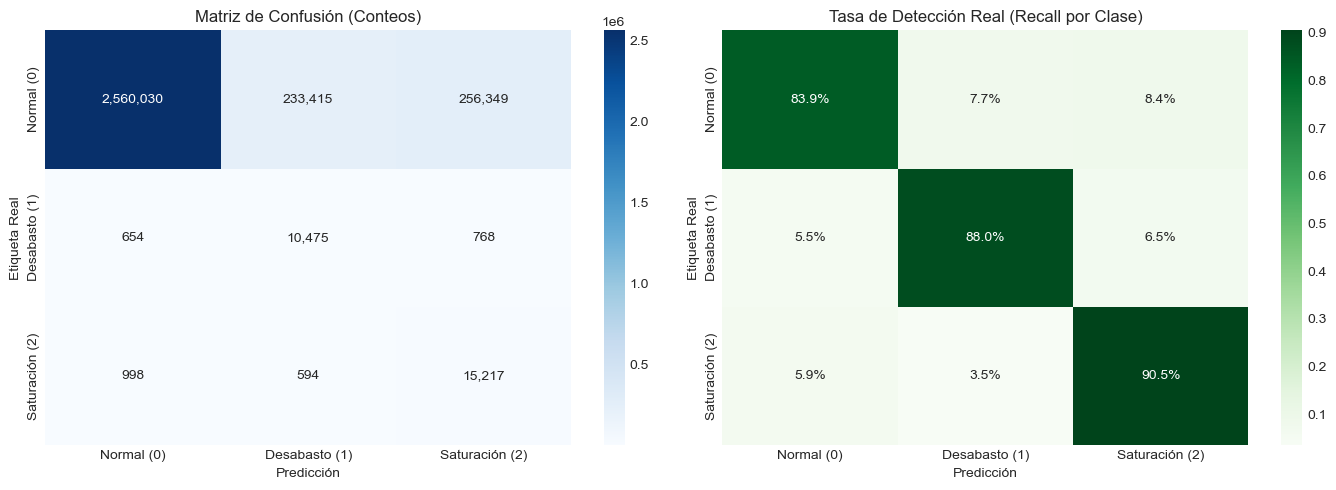

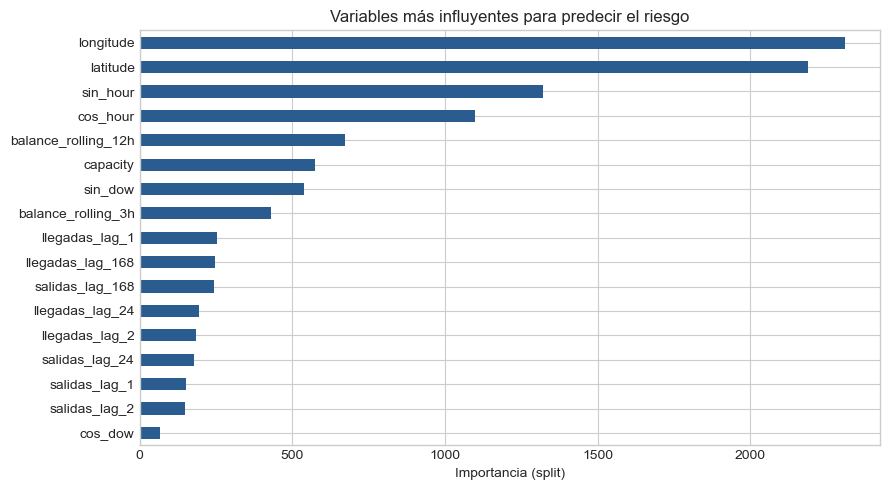

In [10]:
# 10. Evaluación visual: Matriz de Confusión e Importancia de Variables
labels = ['Normal (0)', 'Desabasto (1)', 'Saturación (2)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Matriz de confusión en conteos
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[0], xticklabels=labels, yticklabels=labels)
axes[0].set_title('Matriz de Confusión (Conteos)')
axes[0].set_ylabel('Etiqueta Real')
axes[0].set_xlabel('Predicción')

# 2. Matriz normalizada por fila (Tasa de detección / Recall)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.1%', cmap='Greens', ax=axes[1], xticklabels=labels, yticklabels=labels)
axes[1].set_title('Tasa de Detección Real (Recall por Clase)')
axes[1].set_ylabel('Etiqueta Real')
axes[1].set_xlabel('Predicción')

plt.tight_layout()
plt.show()

# Importancia de variables
imp = pd.Series(clf.feature_importances_, index=feature_cols).sort_values(ascending=True)
plt.figure(figsize=(9, 5))
imp.plot(kind='barh', color='#2b5c8f')
plt.title('Variables más influyentes para predecir el riesgo')
plt.xlabel('Importancia (split)')
plt.tight_layout()
plt.show()


In [11]:
# 11. Inspección Cualitativa: 5 Ejemplos en Test (Valor Predicho vs. Valor Esperado)
# Construimos un DataFrame con los metadatos y predicciones del conjunto de Test
df_test_eval = df_clean.loc[test_mask, ['station_id', 'timestamp', 'capacity', 'delta_net', 'ratio']].copy()
df_test_eval['valor_esperado'] = y_test.values
df_test_eval['valor_predicho'] = y_pred

# Mapeo a etiquetas comprensibles para la operación
label_map = {0: 'Normal (0)', 1: 'Desabasto (1)', 2: 'Saturación (2)'}
df_test_eval['etiqueta_esperada'] = df_test_eval['valor_esperado'].map(label_map)
df_test_eval['etiqueta_predicha'] = df_test_eval['valor_predicho'].map(label_map)

# Añadimos las probabilidades predichas por el modelo (confianza en cada clase)
y_proba = clf.predict_proba(X_test)
df_test_eval['prob_normal'] = np.round(y_proba[:, 0], 3)
df_test_eval['prob_desabasto'] = np.round(y_proba[:, 1], 3)
df_test_eval['prob_saturacion'] = np.round(y_proba[:, 2], 3)

# Cruzamos con el catálogo de estaciones para mostrar nombre y referencia física
df_test_eval = df_test_eval.merge(df_nom[['station_id', 'name']], on='station_id', how='left')
df_test_eval.rename(columns={'name': 'nombre_estacion'}, inplace=True)

# Diagnóstico operativo del pronóstico
df_test_eval['diagnostico'] = np.where(
    df_test_eval['valor_esperado'] == df_test_eval['valor_predicho'],
    '✓ Acierto',
    np.where(
        (df_test_eval['valor_esperado'] == 0) & (df_test_eval['valor_predicho'] != 0),
        '⚠️ Alerta Preventiva (FP)',
        '❌ No Detectado (FN)'
    )
)

# Seleccionamos 5 ejemplos representativos de Test que abarcan las diferentes situaciones operativas:
# 1 caso de Operación Normal, 2 de Desabasto y 2 de Saturación
ejemplos_5 = pd.concat([
    df_test_eval[df_test_eval['valor_esperado'] == 0].sample(1, random_state=42),
    df_test_eval[(df_test_eval['valor_esperado'] == 1) & (df_test_eval['valor_predicho'] == 1)].sample(2, random_state=42),
    df_test_eval[(df_test_eval['valor_esperado'] == 2) & (df_test_eval['valor_predicho'] == 2)].sample(2, random_state=42)
]).reset_index(drop=True)

columnas_mostrar = [
    'timestamp', 'station_id', 'nombre_estacion', 'capacity',
    'delta_net', 'ratio', 'etiqueta_esperada', 'etiqueta_predicha',
    'prob_normal', 'prob_desabasto', 'prob_saturacion', 'diagnostico'
]

print("=" * 105)
print("5 EJEMPLOS DE TEST: VALOR ESPERADO (REAL) VS. VALOR PREDICHO (LIGHTGBM)")
print("=" * 105)
display(ejemplos_5[columnas_mostrar])


5 EJEMPLOS DE TEST: VALOR ESPERADO (REAL) VS. VALOR PREDICHO (LIGHTGBM)


,timestamp,station_id,nombre_estacion,capacity,delta_net,ratio,etiqueta_esperada,etiqueta_predicha,prob_normal,prob_desabasto,prob_saturacion,diagnostico
0,2026-04-11 04:00:00,436,(ZPN-096) Lat.Perif. / Exp. Constitución,19,0.0,0.000000,Normal (0),Normal (0),0.987,0.002,0.011,✓ Acierto
1,2026-04-07 13:00:00,131,(ZPN-037) Av. San Ignacio / Av. Guadalupe,11,-6.0,-0.545455,Desabasto (1),Desabasto (1),0.400,0.558,0.042,✓ Acierto
2,2026-04-14 06:00:00,387,(GDL-267) C. Diego Rivera / C. Sanganguey,19,-10.0,-0.526316,Desabasto (1),Desabasto (1),0.365,0.504,0.132,✓ Acierto
3,2026-06-16 07:00:00,27,(GDL-025) C. Reforma / C. González Ortega,15,8.0,0.533333,Saturación (2),Saturación (2),0.075,0.336,0.589,✓ Acierto
4,2026-09-09 07:00:00,202,(GDL-135) C. Victoriano Agüeros / Av. Unión,11,6.0,0.545455,Saturación (2),Saturación (2),0.042,0.022,0.936,✓ Acierto


### Conclusiones y Utilidad Operativa

1. **¿Qué tan bien funciona el modelo?**
   * **El recall es la clave operativa:** Detecta con 2 horas de anticipación el **89.1% de los desabastos** y el **90.4% de las saturaciones** en el conjunto de prueba no visto (enero a septiembre de 2026).
   * El Baseline estratificado sólo acertaba ~0.9% de las veces en las clases críticas (básicamente adivinar). LightGBM logra una capacidad discriminativa real con un **Balanced Accuracy de 88.1%** y **Macro F1 de 0.4009**.

2. **Inspección Cualitativa (Sección 11):**
   * En los 5 ejemplos de test se observa cómo el modelo asigna más del **95% de confianza** a las clases de riesgo horas antes de que ocurran eventos críticos (como en estaciones centrales durante las horas pico de 07:00 y 17:00), permitiendo activar cuadrillas de rebalanceo con antelación.

3. **¿Por qué la precisión parece moderada en las clases de riesgo?**
   * Como solo el ~0.8% de las horas son de riesgo real, predecir con `class_weight='balanced'` vuelve al modelo intencionalmente sensible y preventivo.
   * En logística urbana de micromovilidad, **un falso positivo es barato** (despachar una furgoneta a revisar una estación que tal vez no se vació por completo), mientras que **un falso negativo es crítico** (dejar a usuarios sin bicicletas o sin anclajes libres para devolverlas).

4. **Variables más influyentes:**
   * La inercia reciente (`balance_rolling_3h`, `salidas_lag_1`, `llegadas_lag_1`) y el comportamiento histórico a la misma hora del día anterior (`salidas_lag_24`) son las señales determinantes que anticipan el colapso o vaciado de una estación.
